In [14]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector

def execute_and_plot(circuit, shots):
    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)


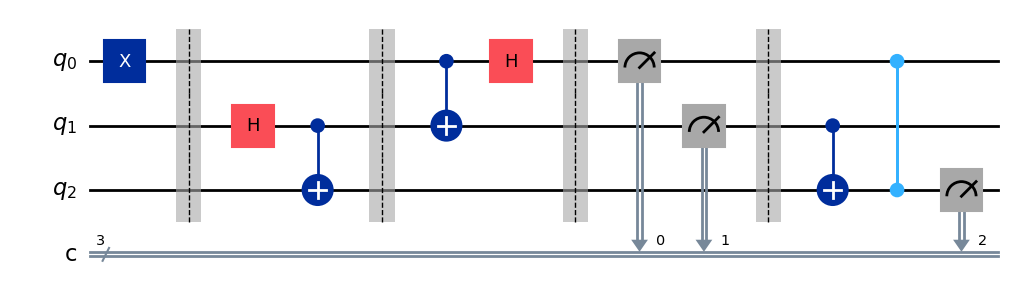

In [17]:
# Quantum Teleportation Circuit Example

from qiskit import QuantumCircuit

# Create a quantum circuit with 3 qubits and 3 classical bits
# Qubit 0: State to teleport (Alice's qubit)
# Qubit 1: Alice's entangled qubit
# Qubit 2: Bob's entangled qubit
circuit = QuantumCircuit(3, 3)

# Step 1: Prepare the state to teleport (e.g., |1⟩)
circuit.x(0)             # You can change this to any state preparation

circuit.barrier()

# Step 2: Create a Bell pair between qubit 1 and qubit 2
circuit.h(1)             # Hadamard on qubit 1
circuit.cx(1, 2)         # CNOT: qubit 1 (control), qubit 2 (target)

circuit.barrier()

# Step 3: Alice entangles her qubits (0 and 1)
circuit.cx(0, 1)         # CNOT: qubit 0 (control), qubit 1 (target)
circuit.h(0)             # Hadamard on qubit 0

circuit.barrier()

# Step 4: Alice measures her qubits and sends the results to Bob
circuit.measure(0, 0)    # Measure qubit 0 into classical bit 0
circuit.measure(1, 1)    # Measure qubit 1 into classical bit 1

circuit.barrier()

# Step 5: Bob applies conditional operations based on Alice's results
circuit.cx(1, 2)         # If classical bit 1 is 1, apply X to qubit 2
circuit.cz(0, 2)         # If classical bit 0 is 1, apply Z to qubit 2

# Step 6: Measure Bob's qubit to verify teleportation
circuit.measure(2, 2)

# Draw the circuit
circuit.draw(output='mpl')

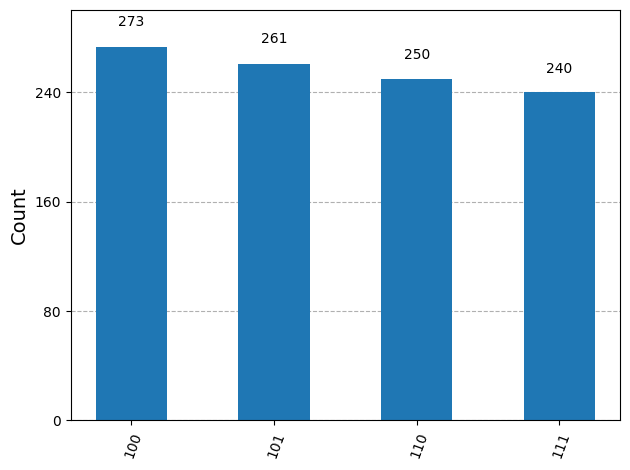

In [16]:
execute_and_plot(circuit, 1024)

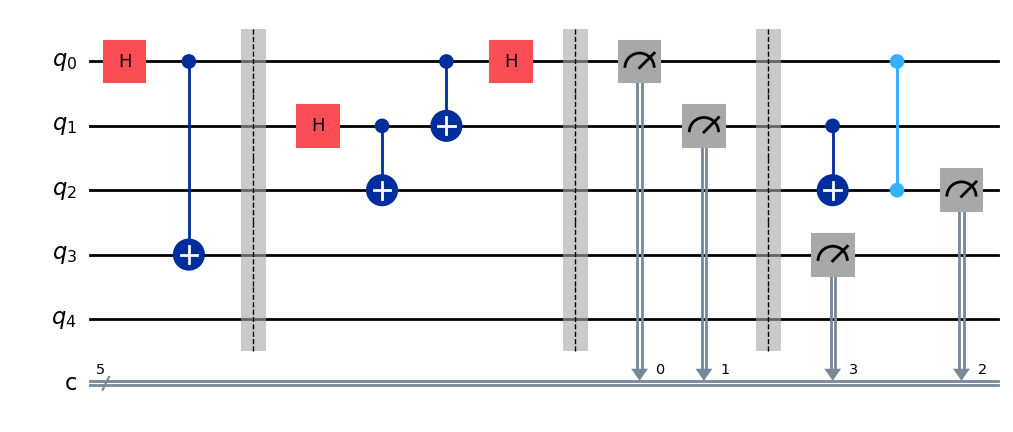

In [ ]:
# Next we will demonstrate quantum teleportation of a qubit which has been entangled with another qubit.
circuit = QuantumCircuit(5, 5)

circuit.h(0)
circuit.cx(0,3)
circuit.barrier()
circuit.h(1)
circuit.cx(1,2)
circuit.cx(0,1)
circuit.h(0)
circuit.barrier()
circuit.measure(0,0)
circuit.measure(1,1)
circuit.barrier()
circuit.cx(1,2)
circuit.cz(0,2)
circuit.measure(2,2)
circuit.measure(3,3)
circuit.draw(output='mpl')

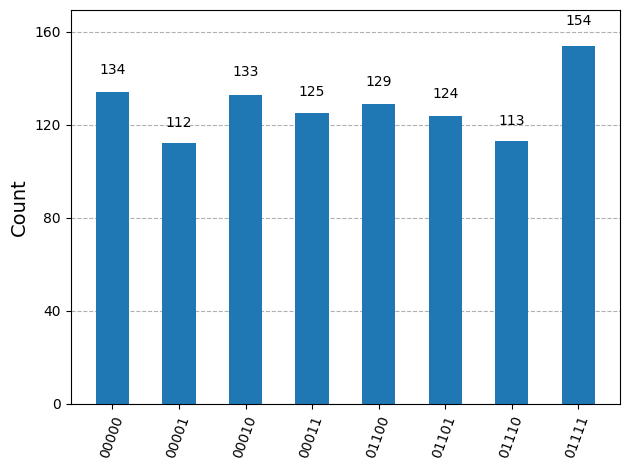

In [5]:
execute_and_plot(circuit, 1024)